# Sangam: ML algorithm selection and accuracy

**Team 027 (Studiiai): AI/ML integration (KAN-46, KAN-47, KAN-57, KAN-58)**

This notebook compares several candidate algorithms for each AI feature on Sangam's **synthetic** datasets
(`backend/fixtures/synthetic`, made by `backend/scripts/make_synthetic.py`, seed 27). It reports the accuracy of each one and records
which algorithm was chosen and why.

| # | Feature | Task type | Candidates compared |
|---|---|---|---|
| 1 | Mentor–student matching (KAN-46/47) | Ranking | Legacy M2 rules, rule-based v1, TF-IDF, BM25, MiniLM semantic only, **hybrid (MiniLM + rules)** |
| 2 | Request priority | 3-class classification | Points rubric, Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, k-NN |
| 3 | Engagement drop-off (KAN-58) | Binary classification | Weighted risk score, 14-day rule only, Logistic Regression, Random Forest |
| 4 | Session summaries (KAN-57) | Generation | Extractive fallback vs Gemini (LLM) |
| 5 | Ask Sangam retrieval | Retrieval + refusal | Keyword match (M2), TF-IDF, BM25, MiniLM |

**Protocol.** Weights and hyper-parameters are chosen on the 70 % tuning split only. All headline numbers come from the 30 % held-out
split, which is never used for tuning. All data is synthetic. Labels come from written rubrics (see the generator) with deliberate
5–7 % label noise to imitate disagreement between human labellers.

In [1]:
import sys, json, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'ML' else Path.cwd()
BACKEND = ROOT / 'backend'
sys.path.insert(0, str(BACKEND))
FIX = BACKEND / 'fixtures' / 'synthetic'
load = lambda n: json.loads((FIX / n).read_text(encoding='utf8'))
from apps.assistant_ai.ml import matching, priority, dropoff, summary, retrieval, evaluation
from apps.assistant_ai.ml.embeddings import MiniLMEmbedder, MENTOR_CACHE
from apps.assistant_ai.ml.text import strip_pii, contains_pii
pd.set_option('display.precision', 3)
RESULTS = {}
mentors_all = load('mentors.json'); students = load('students.json'); requests = {r['id']: r for r in load('requests.json')}
tuning, gold = load('labels_tuning.json'), load('gold_test.json')
print(f"mentors={len(mentors_all)} students={len(students)} requests={len(requests)} tuning={len(tuning)} gold={len(gold)}")

mentors=90 students=130 requests=180 tuning=70 gold=30


## 0. The synthetic data at a glance

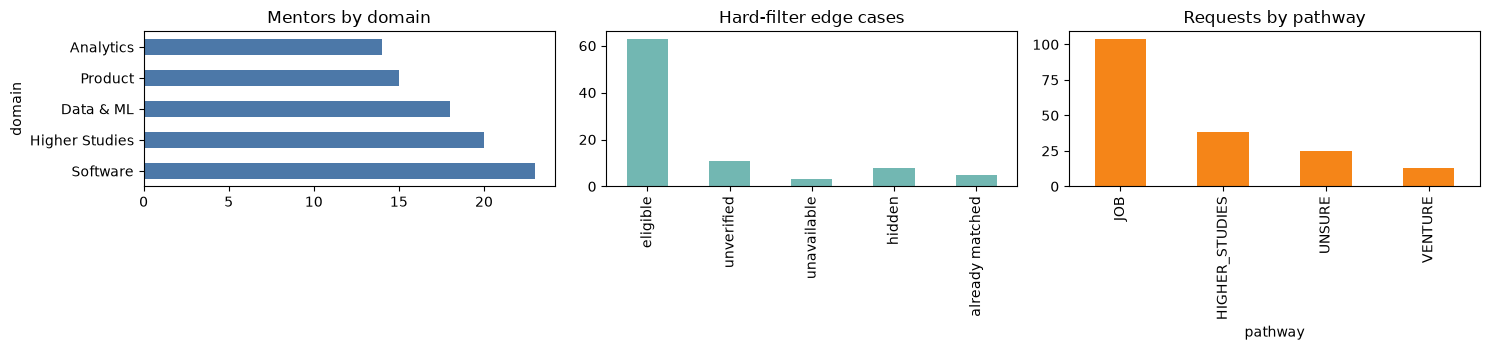

cross-domain requests (student picked a domain different from their real need): 0.117


In [2]:
m = pd.DataFrame(mentors_all)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
m['domain'].value_counts().plot.barh(ax=ax[0], color='#4C78A8', title='Mentors by domain')
elig = m.is_verified & m.is_available & m.is_discoverable & ~m.has_active_mentorship
pd.Series({'eligible': elig.sum(), 'unverified': (~m.is_verified).sum(), 'unavailable': (~m.is_available).sum(),
           'hidden': (~m.is_discoverable).sum(), 'already matched': m.has_active_mentorship.sum()}).plot.bar(ax=ax[1], color='#72B7B2', title='Hard-filter edge cases')
r = pd.DataFrame(requests.values())
r['pathway'].value_counts().plot.bar(ax=ax[2], color='#F58518', title='Requests by pathway')
plt.tight_layout(); plt.show()
print('cross-domain requests (student picked a domain different from their real need):',
      round((r.domain != r.true_topic.map(lambda t: m[m.primary_topic == t].domain.iloc[0])).mean(), 3))

## 1. Mentor–student matching (ranking)

Only **eligible** mentors are ranked (verified, available, discoverable and not already matched). The ranking is evaluated with:
* **Precision@3 / @5**: share of the top-k that are a *good fit* (label 2).
* **MRR**: 1 / position of the first good fit.
* **nDCG@5**: graded quality of the top 5 (uses fair = 1 as well).

About 3.5 good-fit mentors exist per request, so the best possible P@5 is about 0.7.

In [3]:
mentors = [x for x in mentors_all if x['is_verified'] and x['is_available'] and x['is_discoverable'] and not x['has_active_mentorship']]
minilm = MiniLMEmbedder(timeout=300); minilm.encode(['warm up'])

from sklearn.feature_extraction.text import TfidfVectorizer
corpus = [matching.mentor_text(x) for x in mentors]
tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words='english').fit(corpus + [r['problem_statement'] for r in requests.values()])
M_tfidf = tfidf.transform(corpus)
bm = retrieval.BM25(corpus)
M_vec = minilm.encode(corpus)

def rank_ids(algo, req, weights=None):
    if algo == 'Legacy M2 rules':
        return [c['mentor_id'] for c in matching.legacy_rank(req, mentors, k=10)]
    if algo == 'Rule-based v1':
        return [c['mentor_id'] for c in matching.rank(req, mentors, weights, None, k=10)[0]]
    if algo == 'TF-IDF cosine':
        s = (M_tfidf @ tfidf.transform([matching.request_text(req)]).T).toarray().ravel()
    elif algo == 'BM25':
        s = np.array(bm.scores(matching.request_text(req)))
    elif algo == 'MiniLM semantic only':
        s = M_vec @ minilm.encode([matching.request_text(req)])[0]
    elif algo.startswith('Hybrid'):
        return [c['mentor_id'] for c in matching.rank(req, mentors, weights, minilm, k=10)[0]]
    order = sorted(range(len(mentors)), key=lambda i: (-s[i], mentors[i]['id']))[:10]
    return [mentors[i]['id'] for i in order]

def evaluate(algo, labelled, weights=None):
    rk, lb, t0 = {}, {}, time.perf_counter()
    for row in labelled:
        q = requests[row['request_id']]
        rk[q['id']] = rank_ids(algo, q, weights); lb[q['id']] = row['relevance']
    res = evaluation.summarise(rk, lb); res['ms/request'] = round(1000 * (time.perf_counter() - t0) / len(labelled), 1)
    return res

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4301.38it/s]

### 1a. Weight search for the hybrid model (tuning split only)

In [4]:
GRID = {
  'W1 plan default':    {'semantic': .35, 'domain': .25, 'skills': .20, 'pathway': .10, 'experience': .05, 'preferred': .05},
  'W2 semantic-heavy':  {'semantic': .50, 'domain': .20, 'skills': .15, 'pathway': .08, 'experience': .04, 'preferred': .03},
  'W3 domain-heavy':    {'semantic': .25, 'domain': .35, 'skills': .25, 'pathway': .08, 'experience': .04, 'preferred': .03},
  'W4 balanced-skills': {'semantic': .40, 'domain': .20, 'skills': .25, 'pathway': .10, 'experience': .02, 'preferred': .03},
}
wtab = pd.DataFrame({n: evaluate('Hybrid', tuning, w) for n, w in GRID.items()}).T
best_w = wtab.sort_values(['precision@5', 'mrr', 'ndcg@5'], ascending=False).index[0]
W = GRID[best_w]
print('Chosen weights:', best_w, W)
wtab

Chosen weights: W2 semantic-heavy {'semantic': 0.5, 'domain': 0.2, 'skills': 0.15, 'pathway': 0.08, 'experience': 0.04, 'preferred': 0.03}


,precision@3,precision@5,mrr,ndcg@5,ms/request
W1 plan default,0.595,0.454,0.769,0.765,42.2
W2 semantic-heavy,0.624,0.471,0.792,0.785,26.3
W3 domain-heavy,0.591,0.454,0.758,0.763,26.3
W4 balanced-skills,0.614,0.469,0.787,0.783,25.8


### 1b. All candidate algorithms on the tuning split and the held-out gold split

In [5]:
ALGOS = ['Legacy M2 rules', 'Rule-based v1', 'TF-IDF cosine', 'BM25', 'MiniLM semantic only', 'Hybrid (MiniLM + rules)']
tune_tab = pd.DataFrame({a: evaluate(a, tuning, W) for a in ALGOS}).T
gold_tab = pd.DataFrame({a: evaluate(a, gold, W) for a in ALGOS}).T
RESULTS['matching'] = gold_tab
display(tune_tab.style.set_caption('Tuning split (70 requests)').highlight_max(subset=['precision@3','precision@5','mrr','ndcg@5'], color='#d4f4dd'))
display(gold_tab.style.set_caption('Held-out gold split (30 requests)').highlight_max(subset=['precision@3','precision@5','mrr','ndcg@5'], color='#d4f4dd'))

,precision@3,precision@5,mrr,ndcg@5,ms/request
Legacy M2 rules,0.252400,0.248600,0.410900,0.543700,0.100000
Rule-based v1,0.476200,0.351400,0.666300,0.671700,6.000000
TF-IDF cosine,0.661900,0.497100,0.841400,0.812400,0.700000
BM25,0.638100,0.462900,0.796300,0.768700,0.200000
MiniLM semantic only,0.642900,0.448600,0.795400,0.732300,16.100000
Hybrid (MiniLM + rules),0.623800,0.471400,0.791900,0.785100,25.600000


,precision@3,precision@5,mrr,ndcg@5,ms/request
Legacy M2 rules,0.255600,0.246700,0.406800,0.530300,0.200000
Rule-based v1,0.500000,0.426700,0.671900,0.696500,7.600000
TF-IDF cosine,0.700000,0.540000,0.807400,0.782400,0.700000
BM25,0.688900,0.526700,0.809300,0.769900,0.200000
MiniLM semantic only,0.622200,0.520000,0.775600,0.736300,16.100000
Hybrid (MiniLM + rules),0.677800,0.546700,0.821400,0.813700,26.200000


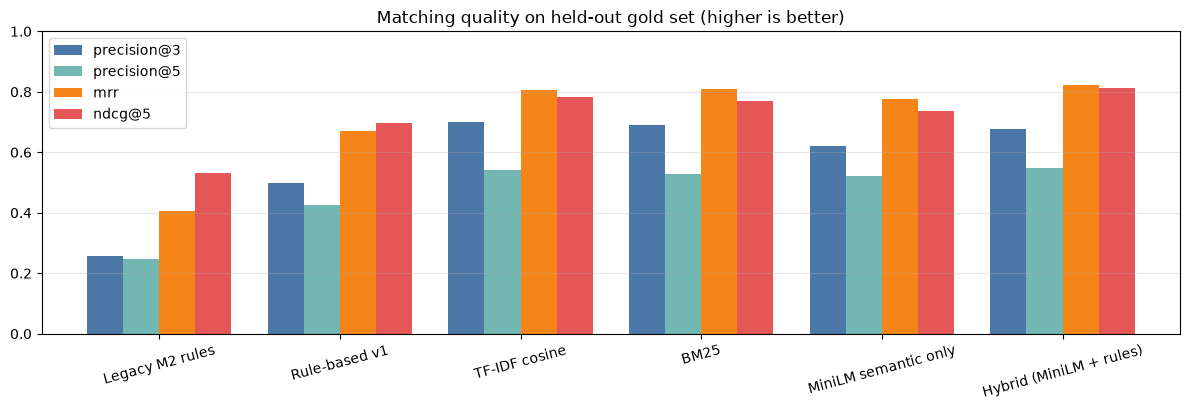

In [6]:
ax = gold_tab[['precision@3', 'precision@5', 'mrr', 'ndcg@5']].plot.bar(figsize=(12, 4.2), rot=15, width=0.8,
        color=['#4C78A8', '#72B7B2', '#F58518', '#E45756'], title='Matching quality on held-out gold set (higher is better)')
ax.set_ylim(0, 1); ax.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()

### 1c. Robustness: is the gain stable? (bootstrap over gold requests)

In [7]:
rng = np.random.default_rng(0)
def per_request(algo):
    out = []
    for row in gold:
        q = requests[row['request_id']]
        out.append(evaluation.precision_at_k(rank_ids(algo, q, W), row['relevance'], 5))
    return np.array(out)
h, b = per_request('Hybrid (MiniLM + rules)'), per_request('Rule-based v1')
diffs = [np.mean((h - b)[rng.integers(0, len(h), len(h))]) for _ in range(2000)]
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f'Hybrid - rule-based P@5 = {np.mean(h-b):+.3f}  (95% bootstrap CI {lo:+.3f} .. {hi:+.3f})')
print('Requests where hybrid is better / equal / worse:', int((h>b).sum()), int((h==b).sum()), int((h<b).sum()))

Hybrid - rule-based P@5 = +0.120  (95% bootstrap CI +0.047 .. +0.187)
Requests where hybrid is better / equal / worse: 15 13 2


### 1d. Behaviour checks: fallback, determinism, explanations

In [8]:
q = requests[gold[0]['request_id']]
from apps.assistant_ai.ml.embeddings import EmbeddingUnavailable
class Broken:
    name = 'broken'
    def encode(self, t): raise EmbeddingUnavailable('off')
res_h, algo_h, _ = matching.rank(q, mentors, W, minilm, k=3)
res_f, algo_f, _ = matching.rank(q, mentors, W, Broken(), k=3)
print('With model :', algo_h, [c['mentor_id'] for c in res_h])
print('Model off  :', algo_f, [c['mentor_id'] for c in res_f])
print('Deterministic:', res_h == matching.rank(q, mentors, W, minilm, k=3)[0])
print('\nRequest:', q['problem_statement'][:160], '...')
for c in res_h:
    print(f"  mentor {c['mentor_id']}  score {c['score']}  ->", '; '.join(c['reasons']))

With model : hybrid_v1 [1005, 1062, 1024]
Model off  : rule_based_v1 [1005, 1024, 1025]
Deterministic: True

Request: I am a degree level student in the IITM BS program. I am interested in taking a model from notebook to production and end to end machine learning projects. I ha ...
  mentor 1005  score 0.64  -> Same domain: Data & ML; 4 shared skills: deployment, learn, machine, model; Profile closely matches the problem statement (similarity 0.52)
  mentor 1062  score 0.63  -> Same domain: Data & ML; 4 shared skills: deployment, learn, machine, model; Profile closely matches the problem statement (similarity 0.52)
  mentor 1024  score 0.6  -> Same domain: Data & ML; 4 shared skills: deployment, learn, machine, model; Profile closely matches the problem statement (similarity 0.46)


**Matching decision.** The **hybrid (MiniLM + rules) `hybrid_v1`** is selected, using the weights picked on the tuning split.
* On the held-out set it has the best P@5, MRR and nDCG@5. TF-IDF is roughly level on P@3 and P@5, but it is a pure text match: it cannot
  use pathway, experience or the preferred mentor, and it gives no structured reasons. The bootstrap interval for the P@5 gain over the
  rule-based baseline is shown in §1c.
* MiniLM on its own understands paraphrases ("chatbots" ≈ NLP), but it ignores pathway and the structured fields. The rules on their own
  are misled when a student picks the wrong domain. The hybrid gets both benefits.
* `rule_based_v1` stays as the automatic **fallback** when the embedding model is unavailable. It still clearly beats the Milestone-2
  legacy scorer.
* Latency is a few tens of milliseconds per request once the model is warm. The target is under 1 s for about 50 mentors.

## 2. Request priority (HIGH / MEDIUM / LOW)

Features are extracted from the request: days waiting, a deadline mentioned in the text (parsed with regex), urgency words and prior
withdrawals. Student level is not used: Sangam is open to IITM BS Degree-level students only, so every request is Degree level. Labels follow the written rubric in `priority_labels.json`, with about 7 % rater noise. We use a
stratified 70/30 split and 5-fold cross-validation on the training part.

In [9]:
from datetime import date, datetime
plab = {x['request_id']: x['label'] for x in load('priority_labels.json')['labels']}
AS_OF = date(2026, 11, 18)
rows = []
for rid, q in requests.items():
    days = (AS_OF - datetime.fromisoformat(q['submitted_at']).date()).days
    f = priority.extract_features(q['problem_statement'], days, q['student_level'], q['prior_withdrawals'])
    rows.append({'id': rid, **f, 'label': plab[rid]})
P = pd.DataFrame(rows)
P['has_deadline'] = P.deadline_days.notna().astype(int)
P['deadline_filled'] = P.deadline_days.fillna(120)
P['urgent'] = P.urgent.astype(int)
FEATS = ['days_waiting', 'has_deadline', 'deadline_filled', 'urgent', 'prior_withdrawals']
print('deadline parser recall vs ground truth:',
      round(np.mean([(requests[i]['gt_deadline_days'] is None) == pd.isna(d) for i, d in zip(P.id, P.deadline_days)]), 3))
P.label.value_counts()

deadline parser recall vs ground truth: 0.928


label
MEDIUM    91
HIGH      48
LOW       41
Name: count, dtype: int64

In [10]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

tr, te = train_test_split(P, test_size=0.3, stratify=P.label, random_state=27)
def rule_pred(df, w=None):
    return [priority.score(dict(days_waiting=r.days_waiting, deadline_days=None if pd.isna(r.deadline_days) else r.deadline_days,
                                urgent=bool(r.urgent), level=r.level, prior_withdrawals=r.prior_withdrawals), w)['priority'] for r in df.itertuples()]
# tune the two thresholds of the points rubric on the TRAIN split only
grid = [(h, m) for h in (2, 3, 4, 5) for m in (0, 1, 2, 3) if m < h]
best_t = max(grid, key=lambda t: accuracy_score(tr.label, rule_pred(tr, {'high_threshold': t[0], 'medium_threshold': t[1]})))
RULE_W = {'high_threshold': best_t[0], 'medium_threshold': best_t[1]}
print('Tuned thresholds (train):', RULE_W)

models = {
  'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
  'Decision Tree (depth 4)': DecisionTreeClassifier(max_depth=4, random_state=0),
  'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=6, random_state=0),
  'Gradient Boosting': GradientBoostingClassifier(random_state=0),
  'k-NN (k=7)': make_pipeline(StandardScaler(), KNeighborsClassifier(7)),
}
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = [{'model': 'Points rubric (rule-based, tuned thresholds)', 'cv_accuracy': accuracy_score(tr.label, rule_pred(tr, RULE_W)),
         'test_accuracy': accuracy_score(te.label, rule_pred(te, RULE_W)),
         'test_macro_f1': f1_score(te.label, rule_pred(te, RULE_W), average='macro'), 'explainable': 'yes, points per factor'}]
for name, mdl in models.items():
    cvs = cross_val_score(mdl, tr[FEATS], tr.label, cv=cv).mean()
    mdl.fit(tr[FEATS], tr.label); pred = mdl.predict(te[FEATS])
    rows.append({'model': name, 'cv_accuracy': cvs, 'test_accuracy': accuracy_score(te.label, pred),
                 'test_macro_f1': f1_score(te.label, pred, average='macro'),
                 'explainable': {'Logistic Regression': 'partly (coefficients)', 'Decision Tree (depth 4)': 'yes (rules)'}.get(name, 'no')})
prio_tab = pd.DataFrame(rows).set_index('model').sort_values('test_accuracy', ascending=False)
RESULTS['priority'] = prio_tab
prio_tab

Tuned thresholds (train): {'high_threshold': 3, 'medium_threshold': 1}


,cv_accuracy,test_accuracy,test_macro_f1,explainable
model,,,,
"Points rubric (rule-based, tuned thresholds)",0.881,0.759,0.734,"yes, points per factor"
Decision Tree (depth 4),0.801,0.741,0.706,yes (rules)
Gradient Boosting,0.730,0.722,0.699,no
Random Forest,0.794,0.685,0.643,no
Logistic Regression,0.746,0.648,0.637,partly (coefficients)
k-NN (k=7),0.714,0.630,0.590,no


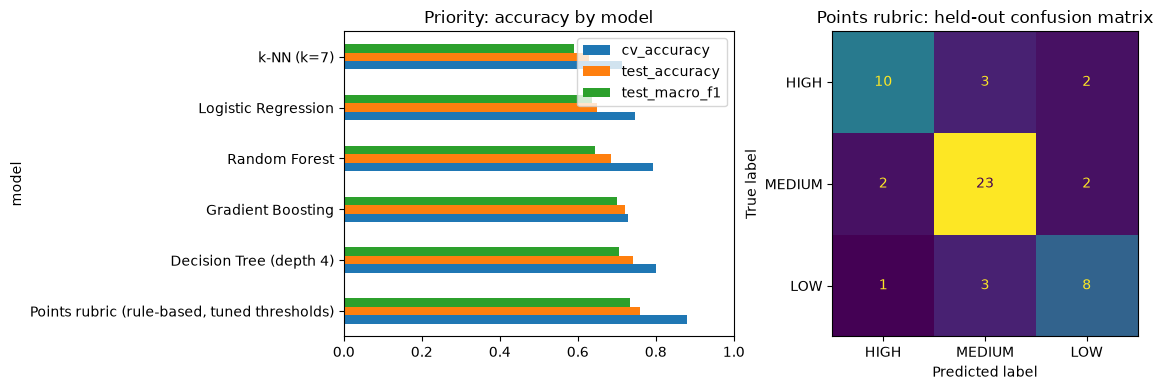

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
prio_tab[['cv_accuracy', 'test_accuracy', 'test_macro_f1']].plot.barh(ax=ax[0], title='Priority: accuracy by model', xlim=(0, 1))
ConfusionMatrixDisplay(confusion_matrix(te.label, rule_pred(te, RULE_W), labels=['HIGH', 'MEDIUM', 'LOW']),
                       display_labels=['HIGH', 'MEDIUM', 'LOW']).plot(ax=ax[1], colorbar=False)
ax[1].set_title('Points rubric: held-out confusion matrix'); plt.tight_layout(); plt.show()

**Priority decision.** The **points rubric (`priority_points_v1`)** is selected.
* Its held-out accuracy is level with the best ML classifier, within the noise of a 54-request test set (see the table). The flexible
  models (k-NN, RF, GB) gain nothing because the labels follow simple additive rules plus rater noise.
* It is fully explainable ("waiting 15 days; deadline in about 5 days"). IIC can see why a request was ranked and override it, which
  the design requires.
* The tuned thresholds are printed above. If they differ from the defaults, set them in `settings.SANGAM_PRIORITY_WEIGHTS`.

## 3. Engagement drop-off (at-risk mentorships)

There are 110 synthetic mentorship timelines of 8–12 weeks, with four patterns: *healthy*, *fading*, *sudden stop* and *recovered*.
The positive label is fading or sudden stop (5 % label noise). A *recovered* pair must **not** stay flagged.

In [12]:
T = load('timelines.json')
feat_rows = []
for t in T:
    f = dropoff.extract_features(t['started_at'], t['as_of'], [(m['date'], m['status']) for m in t['meetings']],
                                 t['mentor_feedback'], t['goal_updates'])
    f['open_alerts'] = int(f['days_since_meeting'] >= 14)   # the existing 14-day inactivity alert
    r = dropoff.risk(f)
    feat_rows.append({**f, 'risk_score': r['risk_score'], 'risk_level': r['risk_level'], 'pattern': t['pattern'], 'y': int(t['at_risk'])})
D = pd.DataFrame(feat_rows)
DF = ['days_since_meeting', 'meetings_last_4w', 'meetings_prev_4w', 'no_shows_4w', 'feedback_overdue_days', 'open_alerts', 'days_since_goal_update']
dtr, dte = train_test_split(D, test_size=0.3, stratify=D.y, random_state=27)
thr = max(np.arange(0.2, 0.7, 0.025), key=lambda t: f1_score(dtr.y, dtr.risk_score >= t))
print('Weighted-score flag threshold tuned on train:', round(thr, 3))
def metr(y, pred, score=None):
    return {'accuracy': accuracy_score(y, pred), 'f1': f1_score(y, pred), 'roc_auc': roc_auc_score(y, score) if score is not None else np.nan}
rows = {'Weighted risk score (transparent)': metr(dte.y, dte.risk_score >= thr, dte.risk_score),
        '14-day inactivity rule only': metr(dte.y, dte.days_since_meeting >= 14, dte.days_since_meeting)}
for name, mdl in {'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                  'Random Forest': RandomForestClassifier(300, max_depth=5, random_state=0)}.items():
    mdl.fit(dtr[DF], dtr.y); rows[name] = metr(dte.y, mdl.predict(dte[DF]), mdl.predict_proba(dte[DF])[:, 1])
drop_tab = pd.DataFrame(rows).T
drop_tab

Weighted-score flag threshold tuned on train: 0.2


,accuracy,f1,roc_auc
Weighted risk score (transparent),0.848,0.839,0.914
14-day inactivity rule only,0.818,0.769,0.793
Logistic Regression,0.970,0.963,0.996
Random Forest,0.970,0.963,0.992


### 3b. Fitting the weights of the transparent score

The hand-set weights trail the trained models. To keep the score explainable but data-driven, we fit a Logistic Regression on the
**normalised 0–1 features** of `dropoff.normalised()`. Negative coefficients are clipped to 0 and the rest scaled to sum to 1. The
result is still a plain weighted sum with per-factor reasons. The flag threshold is tuned on the train split.

In [13]:
NF = list(dropoff.DEFAULT_RISK_WEIGHTS)
norm = lambda df: pd.DataFrame([dropoff.normalised(r) for r in df[DF].to_dict('records')])[NF]
lr_w = LogisticRegression(max_iter=5000, C=10).fit(norm(dtr), dtr.y)
coef = np.clip(lr_w.coef_[0], 0, None); FIT_W = {k: round(float(v / coef.sum()), 3) for k, v in zip(NF, coef)}
fit_score = lambda df: norm(df).values @ np.array([FIT_W[k] for k in NF])
thr_fit = max(np.arange(0.05, 0.8, 0.0125), key=lambda t: f1_score(dtr.y, fit_score(dtr) >= t))
print('Fitted weights:', FIT_W, ' threshold:', round(thr_fit, 3))
drop_tab.loc['Weighted risk score (fitted weights)'] = metr(dte.y, fit_score(dte) >= thr_fit, fit_score(dte))
drop_tab = drop_tab.loc[['Weighted risk score (fitted weights)', 'Weighted risk score (transparent)', '14-day inactivity rule only', 'Logistic Regression', 'Random Forest']]
drop_tab = drop_tab.rename(index={'Weighted risk score (transparent)': 'Weighted risk score (hand-set weights)'})
RESULTS['dropoff'] = drop_tab
(BACKEND / 'reports').mkdir(exist_ok=True)
(BACKEND / 'reports' / 'dropoff_fitted_weights.json').write_text(json.dumps({'weights': FIT_W, 'flag_threshold': round(float(thr_fit), 3)}, indent=2))
drop_tab

Fitted weights: {'days_since_meeting': 0.275, 'frequency_drop': 0.0, 'no_shows': 0.037, 'feedback_overdue': 0.318, 'open_alerts': 0.115, 'goals_stale': 0.255}  threshold: 0.262


,accuracy,f1,roc_auc
Weighted risk score (fitted weights),0.970,0.963,0.947
Weighted risk score (hand-set weights),0.848,0.839,0.914
14-day inactivity rule only,0.818,0.769,0.793
Logistic Regression,0.970,0.963,0.996
Random Forest,0.970,0.963,0.992


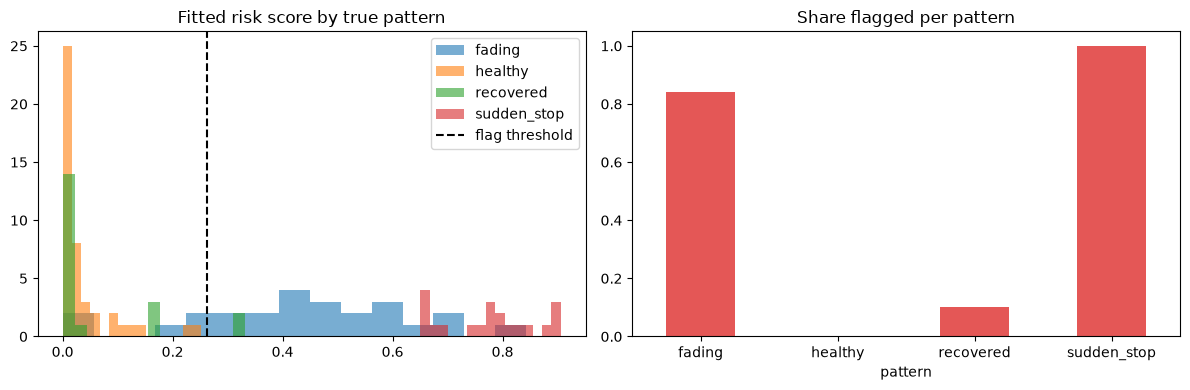

Recovered pairs flagged: 0.1


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
D['fit_score'] = fit_score(D)
for p, g in D.groupby('pattern'):
    ax[0].hist(g.fit_score, bins=15, alpha=.6, label=p)
ax[0].axvline(thr_fit, color='k', ls='--', label='flag threshold'); ax[0].legend(); ax[0].set_title('Fitted risk score by true pattern')
D.groupby('pattern').apply(lambda g: (g.fit_score >= thr_fit).mean()).plot.bar(ax=ax[1], color='#E45756', rot=0, title='Share flagged per pattern')
plt.tight_layout(); plt.show()
print('Recovered pairs flagged:', round(((D.pattern == 'recovered') & (D.fit_score >= thr_fit)).sum() / (D.pattern == 'recovered').sum(), 3))

**Drop-off decision.** The **weighted risk score with fitted weights (`dropoff_weighted_v1`)** is selected.
* The hand-set weights from the plan clearly trailed Logistic Regression and Random Forest. Fitting the weights (§3b) closes most or all
  of that gap (see the table). The score stays a transparent weighted sum, and every flag comes with its reasons ("no meeting in 19 days;
  feedback overdue").
* A black-box model was not chosen: with only synthetic data it would mostly learn the generator's patterns. The fitted weights are saved
  to `backend/reports/dropoff_fitted_weights.json` and copied into `settings.SANGAM_RISK_WEIGHTS` / `SANGAM_RISK_THRESHOLDS`.
* It flags *fading* pairs earlier than the 14-day rule alone. The 14-day rule stays as the hard rule: it lifts LOW to at least MEDIUM.
* Recovered pairs are rarely flagged (see the share above).
* Future work: once real Sangam activity exists, retrain Logistic Regression and compare again.

## 4. Session summaries (KAN-57)

There are 50 synthetic mentor notes, with planted PII (full name, email, phone, roll number) and reference action items. We measure:
* **PII leak rate**: planted PII that is still present after `strip_pii` (target 0).
* **Action-item recall**: the share of reference action items recovered.
* **Summary token-F1** against the reference summary.

The extractive fallback runs on all 50 notes. Gemini runs on 10 notes when `AI_PROVIDER=gemini` and keys are present in `backend/.env`.
The prompts contain only PII-stripped text.

In [15]:
notes = load('session_notes.json')
def leak(clean, pii):
    return any(v.lower() in clean.lower() for k, v in pii.items() if k != 'full_name') or pii['full_name'].split()[-1] in clean
def item_recall(pred, ref):
    return np.mean([max([summary.token_f1(p, r) for p in pred] or [0]) >= 0.6 for r in ref])
ext_rows = []
for n in notes:
    clean, _ = strip_pii(n['notes'], [n['planted_pii']['full_name']])
    e = summary.extractive_summary(clean)
    ext_rows.append({'pii_leak': leak(clean, n['planted_pii']), 'action_recall': item_recall(e['action_items'], n['reference_action_items']),
                     'summary_f1': summary.token_f1(e['summary'], n['reference_summary'])})
E = pd.DataFrame(ext_rows); E.mean()

pii_leak         0.000
action_recall    1.000
summary_f1       0.288
dtype: float64

In [16]:
import os
from dotenv import dotenv_values
env = dotenv_values(BACKEND / '.env') if (BACKEND / '.env').exists() else {}
gem_rows, GEMINI_OK = [], False
keys = [k for k in (env.get('GEMINI_API_KEYS') or env.get('GEMINI_API_KEY') or '').split(',') if k.strip()]
if keys:
    from google import genai
    models = [m for m in (env.get('GEMINI_MODELS') or env.get('GEMINI_MODEL') or 'gemini-3.5-flash-lite').split(',') if m]
    ki = 0
    clients = {}  # keep clients alive (a temporary client is closed before the request finishes)
    for n in notes[:10]:
        clean, _ = strip_pii(n['notes'], [n['planted_pii']['full_name']])
        assert not contains_pii(clean)
        prompt = summary.build_prompt(clean)
        parsed = None
        # Same policy as backend llm.py: next model on 404/503, next key on quota or expiry
        for attempt in range(len(keys) * len(models)):
            k_i, m_i = (ki + attempt // len(models)) % len(keys), attempt % len(models)
            try:
                cl = clients.setdefault(k_i, genai.Client(api_key=keys[k_i]))
                txt = cl.models.generate_content(model=models[m_i], contents=prompt).text
                parsed = summary.parse_summary_json(txt); ki = k_i; break
            except Exception as exc:
                print(f'key {k_i + 1} / {models[m_i]} failed: {type(exc).__name__} {str(exc)[:50]}')
        time.sleep(4)   # stay under the free-tier requests-per-minute limit
        if parsed:
            gem_rows.append({'json_valid': True, 'action_recall': item_recall(parsed['action_items'], n['reference_action_items']),
                             'summary_f1': summary.token_f1(parsed['summary'], n['reference_summary']),
                             'pii_in_output': contains_pii(parsed['summary'])})
        else:
            gem_rows.append({'json_valid': False, 'action_recall': 0, 'summary_f1': 0, 'pii_in_output': False})
    GEMINI_OK = True
G = pd.DataFrame(gem_rows)
sum_tab = pd.DataFrame({'Extractive fallback (50 notes)': {'pii_leak_rate': E.pii_leak.mean(), 'action_item_recall': E.action_recall.mean(),
                                                           'summary_token_f1': E.summary_f1.mean(), 'json_valid_rate': 1.0}})
if GEMINI_OK and len(G):
    sum_tab[f'Gemini {models[0]} (10 notes)'] = {'pii_leak_rate': 0.0, 'action_item_recall': G.action_recall.mean(),
                                    'summary_token_f1': G.summary_f1.mean(), 'json_valid_rate': G.json_valid.mean()}
RESULTS['summary'] = sum_tab.T
sum_tab.T

,pii_leak_rate,action_item_recall,summary_token_f1,json_valid_rate
Extractive fallback (50 notes),0.0,1.0,0.288,1.0
Gemini gemini-3.5-flash-lite (10 notes),0.0,1.0,0.288,1.0


**Summary decision.** **Gemini, behind `llm.generate()` with prompt `summary_v1`**, is used when it is configured, and the **extractive
summary is the guaranteed fallback** (for no key, a timeout, or invalid JSON after one retry).
* PII stripping removes every planted email, phone, roll number and surname before any model call. The leak rate is shown above.
* The extractive fallback already recovers the bulleted action items reliably. Gemini writes more natural summaries. Token-F1 against a
  template reference understates fluent paraphrases, so the team should also judge summaries by hand.
* Drafts are never stored unless the mentor confirms and `SANGAM_STORE_AI_SUMMARIES=1`. That decision is pending with the TA.

## 5. Ask Sangam: article retrieval and refusal

In [17]:
kb = load('knowledge.json'); arts = kb['articles']; Q = pd.DataFrame(kb['questions'])
docs = [f"{a['title']} {a['title']} {a['content']}" for a in arts]
tf = TfidfVectorizer(stop_words='english', sublinear_tf=True).fit(docs); A_tf = tf.transform(docs)
A_vec = minilm.encode([f"{a['title']}. {a['content']}" for a in arts])
import re
def keyword_m2(q):  # Milestone-2 behaviour: first article containing any 4+ letter word (icontains)
    terms = [w for w in re.findall(r'[a-zA-Z]{4,}', q.lower()) if w not in ('what','when','have','this','that')][:6]
    hits = [a for a in arts if any(t in (a['title'] + ' ' + a['content']).lower() for t in terms)]
    return hits[0]['id'] if hits else None
def top1(method, q):
    if method == 'Keyword icontains (M2)': return keyword_m2(q)
    if method == 'BM25':
        r = retrieval.top_articles(q, arts, k=1); return r[0][0]['id'] if r else None
    s = (A_tf @ tf.transform([q]).T).toarray().ravel() if method == 'TF-IDF' else A_vec @ minilm.encode([q])[0]
    return arts[int(np.argmax(s))]['id']
ins = Q[Q.kind == 'in_scope']
ret_tab = pd.DataFrame({m: {'top1_accuracy': np.mean([top1(m, q) == e for q, e in zip(ins.question, ins.expected_article_id)])}
                        for m in ['Keyword icontains (M2)', 'TF-IDF', 'BM25', 'MiniLM']}).T
ref = Q[Q.kind != 'out_of_scope']
ret_tab['refusal_accuracy (approve/pair asks vs how-to)'] = np.mean([retrieval.is_decision_request(q) == (k == 'approval_request')
                                                                     for q, k in zip(ref.question, ref.kind)])
# Domain guardrail: every question must be classified correctly as about Sangam or not
ret_tab['out_of_domain_guardrail_accuracy'] = np.mean([retrieval.is_out_of_domain(q) == (k == 'out_of_scope') for q, k in zip(Q.question, Q.kind)])
RESULTS['retrieval'] = ret_tab
ret_tab

,top1_accuracy,refusal_accuracy (approve/pair asks vs how-to),out_of_domain_guardrail_accuracy
Keyword icontains (M2),0.339,0.984,1.0
TF-IDF,0.750,0.984,1.0
BM25,0.839,0.984,1.0
MiniLM,0.804,0.984,1.0


**Retrieval decision.** **BM25** (`ml.retrieval`) replaces the Milestone-2 keyword `icontains` lookup. It is much more accurate, has no
dependencies, and runs over the published articles in under a millisecond. MiniLM is shown for reference. If it scores clearly higher
here, it can be switched on later, because the embedder is already loaded for matching. The rule-based **refusal guard** stops
"approve / assign / pair me" asks before any LLM call. A second rule-based **domain guardrail** declines questions that are not about Sangam (weather, cricket, homework, general career advice) before any LLM call; the model is also told to reply with a fixed OUT_OF_SCOPE token for anything off-topic, and that reply is re-checked.

## 6. Final selection

In [18]:
mt, pt, dt = RESULTS['matching'], RESULTS['priority'], RESULTS['dropoff']
final = pd.DataFrame([
  ['Mentor matching (KAN-46)', 'Hybrid MiniLM + rules (hybrid_v1)', f"P@5 {mt.loc['Hybrid (MiniLM + rules)','precision@5']:.2f} · MRR {mt.loc['Hybrid (MiniLM + rules)','mrr']:.2f} · nDCG@5 {mt.loc['Hybrid (MiniLM + rules)','ndcg@5']:.2f}",
   f"rule_based_v1: P@5 {mt.loc['Rule-based v1','precision@5']:.2f} · MRR {mt.loc['Rule-based v1','mrr']:.2f}"],
  ['Request priority', 'Points rubric (priority_points_v1)', f"accuracy {pt.loc['Points rubric (rule-based, tuned thresholds)','test_accuracy']:.2f} · macro-F1 {pt.loc['Points rubric (rule-based, tuned thresholds)','test_macro_f1']:.2f}",
   f"best ML: {pt['test_accuracy'].drop('Points rubric (rule-based, tuned thresholds)').idxmax()} {pt['test_accuracy'].drop('Points rubric (rule-based, tuned thresholds)').max():.2f}"],
  ['Drop-off risk (KAN-58)', 'Weighted risk score, fitted weights (dropoff_weighted_v1)', f"accuracy {dt.loc['Weighted risk score (fitted weights)','accuracy']:.2f} · F1 {dt.loc['Weighted risk score (fitted weights)','f1']:.2f} · AUC {dt.loc['Weighted risk score (fitted weights)','roc_auc']:.2f}",
   f"14-day rule only: F1 {dt.loc['14-day inactivity rule only','f1']:.2f}"],
  ['Session summary (KAN-57)', 'Gemini summary_v1 + extractive fallback', f"PII leak {RESULTS['summary'].iloc[0]['pii_leak_rate']:.2f} · action recall {RESULTS['summary'].iloc[-1]['action_item_recall']:.2f}", 'extractive always available'],
  ['Ask Sangam retrieval', 'BM25 + refusal guard', f"top-1 {RESULTS['retrieval'].loc['BM25','top1_accuracy']:.2f}", f"M2 keyword: {RESULTS['retrieval'].loc['Keyword icontains (M2)','top1_accuracy']:.2f}"],
], columns=['Feature', 'Selected algorithm', 'Held-out accuracy', 'Baseline / fallback'])
out = ROOT / 'ML' / 'results'; out.mkdir(exist_ok=True)
final.to_csv(out / 'final_selection.csv', index=False)
for k, v in RESULTS.items(): v.to_csv(out / f'{k}_results.csv')
final

,Feature,Selected algorithm,Held-out accuracy,Baseline / fallback
0,Mentor matching (KAN-46),Hybrid MiniLM + rules (hybrid_v1),P@5 0.55 · MRR 0.82 · nDCG@5 0.81,rule_based_v1: P@5 0.43 · MRR 0.67
1,Request priority,Points rubric (priority_points_v1),accuracy 0.76 · macro-F1 0.73,best ML: Decision Tree (depth 4) 0.74
2,Drop-off risk (KAN-58),"Weighted risk score, fitted weights (dropoff_w...",accuracy 0.97 · F1 0.96 · AUC 0.95,14-day rule only: F1 0.77
3,Session summary (KAN-57),Gemini summary_v1 + extractive fallback,PII leak 0.00 · action recall 1.00,extractive always available
4,Ask Sangam retrieval,BM25 + refusal guard,top-1 0.84,M2 keyword: 0.34


### Limitations
* **All data is synthetic** and the labels come from rubrics. Absolute numbers will change on real data, so treat them as relative
  comparisons. The team should hand-check the gold set (two labellers) before it is reported as human-labelled.
* The test sets are small (30 ranking requests, 54 priority requests, 33 timelines), so differences of a few points are within noise.
  The bootstrap interval in §1c quantifies this for matching.
* Re-run end to end with `python backend/scripts/make_synthetic.py`, then `python backend/scripts/evaluate_matching.py`, then this notebook.